In [1]:
pip install tensorflow matplotlib

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/384.1 MB 3.8 MB/s eta 0:01:42
   ---------------------------------------- 0.8/384.1 MB 4.7 MB/s eta 0:01:23
   ---------------------------------------- 4.2/384.1 MB 8.1 MB/s eta 0:00:47
    --------------------------------------- 5.8/384.1 MB 8.0 MB/s eta 0:00:48
    --------------------------------------- 7.1/384.1 MB 7.5 MB/s eta 0:00:51
    --------------------------------------- 7.9/384.1 MB 7.2 MB/s eta 0:00:53
    --------------------------------------- 8.9/384.1 MB 6.6 MB/s eta 0:00:57
   - -------------------------------------- 9.7/384.1 MB 6.3 MB/s eta 0:01:00
   - -------------------------------------- 10.7/384.1 MB 6.1 MB/s eta 0:01:02
   - -------------------------------------- 11.5/384.1 MB 5.9 MB/s eta 0:01:03
   - -------------------------------------- 12.6/384.1 MB 5.8 MB/s eta 0:01:05
   - -------------------------------------- 13.4/384.1 MB 5.7 MB/s e

In [2]:
import json
import pathlib

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.22.0-rc0
GPU: []


In [7]:
DATA_DIR = "dataset"        
IMG_SIZE = (128, 128)       
BATCH_SIZE = 32             
EPOCHS = 25                 

MODEL_PATH = "fruit_model.keras"
CLASSES_PATH = "class_names.json"

Found 3115 files belonging to 36 classes.
Found 351 files belonging to 36 classes.
Классы: ['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', 'onion', 'orange', 'paprika', 'pear', 'peas', 'pineapple', 'pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


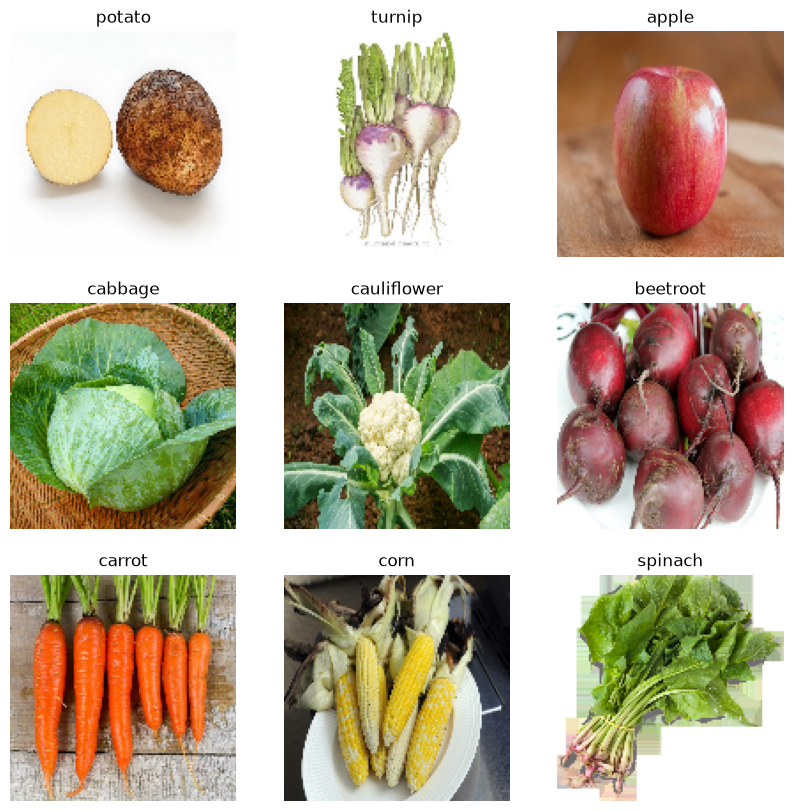

In [8]:
data_dir = pathlib.Path(DATA_DIR)
train_dir = data_dir / "train"
val_dir = data_dir / "validation"

common = dict(image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)

if train_dir.exists() and val_dir.exists():
    train_ds = tf.keras.utils.image_dataset_from_directory(train_dir, shuffle=True, **common)
    val_ds = tf.keras.utils.image_dataset_from_directory(val_dir, shuffle=False, **common)
else:
    root = train_dir if train_dir.exists() else data_dir
    train_ds = tf.keras.utils.image_dataset_from_directory(
        root, validation_split=0.2, subset="training", **common)
    val_ds = tf.keras.utils.image_dataset_from_directory(
        root, validation_split=0.2, subset="validation", **common)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Классы:", class_names)

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

In [10]:
augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         9,252 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 463,460 (1.77 MB)

 Trainable params: 463,460 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH, monitor="val_accuracy", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/25


C:\Users\den-k\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


98/98 ━━━━━━━━━━━━━━━━━━━━ 18s 168ms/step - accuracy: 0.0571 - loss: 3.4311 - val_accuracy: 0.1197 - val_loss: 3.1338
Epoch 2/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 124ms/step - accuracy: 0.1027 - loss: 3.0915 - val_accuracy: 0.1567 - val_loss: 2.7912
Epoch 3/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step - accuracy: 0.1647 - loss: 2.8174 - val_accuracy: 0.2393 - val_loss: 2.4071
Epoch 4/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step - accuracy: 0.1823 - loss: 2.6683 - val_accuracy: 0.2963 - val_loss: 2.2853
Epoch 5/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 123ms/step - accuracy: 0.2058 - loss: 2.5814 - val_accuracy: 0.3362 - val_loss: 2.1245
Epoch 6/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 123ms/step - accuracy: 0.2343 - loss: 2.4886 - val_accuracy: 0.3533 - val_loss: 2.0659
Epoch 7/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.2327 - loss: 2.4408 - val_accuracy: 0.4160 - val_loss: 1.9936
Epoch 8/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.2632 - loss: 2.3698 - val_accuracy: 0.421

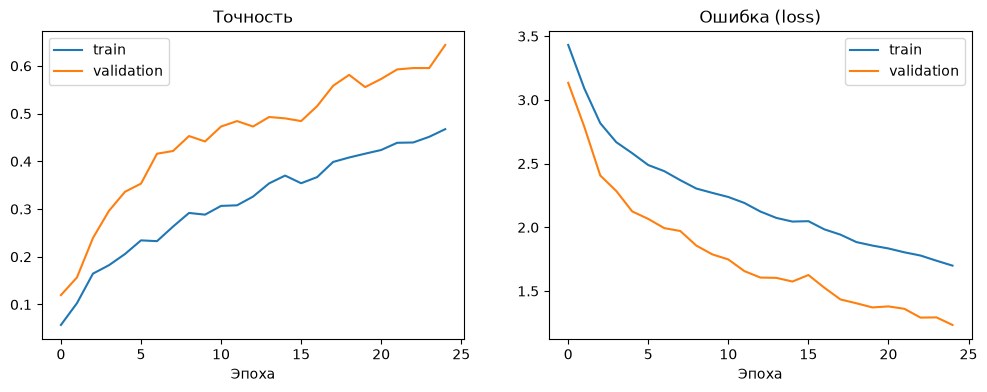

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Точность")
ax[0].set_xlabel("Эпоха")
ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Ошибка (loss)")
ax[1].set_xlabel("Эпоха")
ax[1].legend()

plt.show()

In [13]:
model.save(MODEL_PATH)
with open(CLASSES_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

print("Сохранено:", MODEL_PATH, "и", CLASSES_PATH)

Сохранено: fruit_model.keras и class_names.json


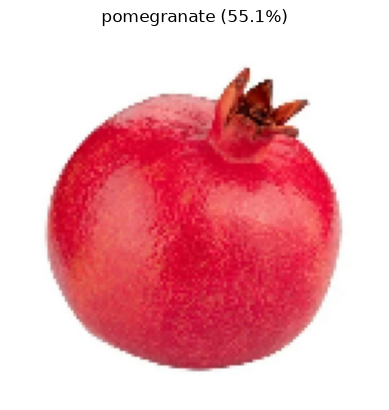

pomegranate           55.1%
apple                 31.7%
chilli pepper          4.9%


In [18]:
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

IMG_SIZE = (128, 128)
model = tf.keras.models.load_model("fruit_model.keras")
with open("class_names.json", encoding="utf-8") as f:
    class_names = json.load(f)


def predict_image(path, top_k=3):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img)[np.newaxis, ...]
    probs = model.predict(arr, verbose=0)[0]
    top = np.argsort(probs)[::-1][:top_k]

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{class_names[top[0]]} ({probs[top[0]] * 100:.1f}%)")
    plt.show()

    for i in top:
        print(f"{class_names[i]:<20} {probs[i] * 100:5.1f}%")


predict_image("photo.jpg")   

In [19]:
test_dir = pathlib.Path(DATA_DIR) / "test"
if test_dir.exists():
    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
    loss, acc = model.evaluate(test_ds)
    print(f"Точность на тесте: {acc * 100:.1f}%")
else:
    print("Папки test нет, пропускаем.")

Found 359 files belonging to 36 classes.
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.6435 - loss: 1.2359
Точность на тесте: 64.3%
